# 12 - DSO view: an LV feeder with heat-pump, PV and EV fleets

A distribution system operator (DSO) cares about three questions on a low-voltage (LV) feeder:
**Are the bus voltages inside the limits?** **Is the transformer or a cable overloaded?**
**How much more heat pumps and rooftop PV can the feeder host before either happens?**

This notebook answers them with energysim, in three steps:

1. **A pandapower LV feeder.** A 20/0.4 kV transformer (`0.63 MVA 20/0.4 kV`, a standard type
   from pandapower) feeds eight load buses `B1 ... B8` along a radial `NAYY 4x150 SE` cable. Every
   element has a unique name, which is how energysim addresses variables (`"<element>.<column>"`).
2. **Fleets of homes on every bus.** Each bus has
   - a *base load* signal (the non-controllable household load),
   - a compact **heat-pump + 1R1C building fleet** (thermostat, COP as a lookup of outdoor temperature),
   - a compact **smart-PV fleet** that curtails its output with a **volt-watt** curve on the bus voltage,
   - a built-in **`BatteryFleetAdapter`** acting as home EV chargers that start charging when the
     evening plug-in signal rises.

   The fleet totals (kW) are summed into the pandapower load and sgen `p_mw` inputs of their bus.
3. **Ensemble study.** We sweep PV penetration, heat-pump penetration and the volt-watt function on/off,
   and collect the KPIs that matter for a DSO: maximum and minimum voltage, maximum transformer loading and
   the share of bus-time outside the statutory band 0.95 to 1.05 pu.

## Equations and assumptions

* **Building (1R1C, per home i):** `C_i dT_i/dt = Q_heat,i - (T_i - T_amb) / R_i`, explicit Euler at the
  15-minute macro step (`R C` is about 50 to 160 h, so the step is far below the time constant).
* **Thermostat:** on below `T_set - 0.5 K`, off above `T_set + 0.5 K`, otherwise unchanged.
* **Heat pump electric power:** `P_el = Q_heat / COP(T_amb)`, with `COP` an illustrative lookup curve.
* **PV available power:** `P_av = P_peak * G/1000 * [1 + gamma (T_cell - 25)] * PR`.
* **Volt-watt:** `P_pv = P_av * f(v)`, where `f` equals 1 up to 1.03 pu, falls to 0.6 at 1.06 pu and to 0 at 1.10 pu.
  The voltage `v` is the bus voltage that pandapower reports at the previous macro step, so the loop has a
  macro-step delay. The applied factor follows the target with a first-order response of 30 min
  (`f += (1 - exp(-h/30 min)) (f_target - f)`). Without that response a hard switch with a delay chatters between 0
  and full output; the 30-min response is an assumption about the aggregate fleet, not a standards value.
* **EV charging:** a 3.7 kW wall box per car on about 16 % of homes (4 cars per bus), no vehicle-to-grid
  (`max_discharge = 0`), charging stops automatically at 95 % state of charge. The load profiles are not diversified
  beyond this, so a larger EV share quickly overloads the 0.63 MVA transformer at night.
* **Reactive power:** all loads and PV are modelled at unity power factor (`q_mvar = 0`). This is a simplification:
  reactive power from heat pumps and inverters would raise voltage drops, so the voltage results are optimistic.
* **Parameters are illustrative.** Replace the cable type, transformer rating, COP curve and load profiles with
  network and metering data before using the numbers for planning.

All fleet parameters are drawn from fixed random seeds, so every run is reproducible.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import pandapower as pp

from energysim import world, Ensemble
from energysim.ensemble import Grid
from energysim.container import BatteryFleetAdapter

## The fleet models

The two compact fleets below are shared with notebook 14 and are written as `VectorizedContainerAdapter`
subclasses, so one step updates all homes with NumPy operations. The source of each one lives in
`scripts/notebook_src/snippets/`. The heat-pump fleet takes a `cop_curve` argument, which notebook 14 uses to
model a COP that collapses in deep cold.

In [2]:
# --- Compact heat-pump + 1R1C building fleet (shared by notebooks 12 and 14) -------------------
import numpy as np
from energysim.container import VectorizedContainerAdapter
from energysim.models.common import Curve1D

#: Illustrative COP(T_amb) for an air-source heat pump at 35 C flow (replace with test data).
HP_COP_MILD = Curve1D([-15, -7, 2, 7, 12], [2.2, 2.6, 3.2, 3.7, 4.2], name="COP_mild")


class HeatPumpFleet(VectorizedContainerAdapter):
    """N heat-pump homes: 1R1C envelope, thermostat with hysteresis, COP(T_amb) lookup.

    Per home i (explicit Euler, step h):

        C_i dT_i/dt = Q_heat_i - (T_i - T_amb) / R_i
        on_i  : switches on below  T_set - db/2, off above T_set + db/2 (hysteresis)
        Q_heat_i = on_i * Qmax_i * dr_limit                      [kW heat]
        P_el_i   = Q_heat_i / COP(T_amb)                         [kW electric]

    ``dr_limit`` (0..1) is a demand-response input that caps the compressor capacity; a
    value of 0 switches the fleet off (homes cool down through their envelope).

    Parameters are drawn per home from uniform ranges with a fixed seed, so runs are
    deterministic.  Setting ``q_heat_max_kw`` to 0 for a home removes its heat pump
    (used for the penetration sweeps).

    Inputs : t_ambient_degc [degC], dr_limit [1]
    States : t_indoor [degC], on [0/1], p_kw [kW], q_heat_kw [kW], cop [1]
    Totals : total_p_kw, total_q_heat_kw, mean_t_indoor, min_t_indoor (via the container)
    """

    units = {
        "t_ambient_degc": "degC", "dr_limit": "1",
        "t_indoor": "degC", "on": "1", "p_kw": "kW", "q_heat_kw": "kW", "cop": "1",
    }

    def __init__(self, name="hp_fleet", size=100, cop_curve=HP_COP_MILD, setpoint_degc=20.0,
                 deadband_k=1.0, q_heat_max_kw=None, rng_seed=0, t_init_degc=20.0,
                 step_size=900.0, **kwargs):
        super().__init__(name=name, size=size, step_size=step_size)
        rng = np.random.default_rng(rng_seed)
        self.c_th = rng.uniform(8.0, 16.0, self.size)                  # kWh/K
        self.r_th = rng.uniform(6.0, 10.0, self.size)                  # K/kW
        qmax = rng.uniform(4.0, 7.0, self.size) if q_heat_max_kw is None else \
            self._as_vector(q_heat_max_kw, "q_heat_max_kw")
        self.q_max = np.asarray(qmax, dtype=float)                     # kW heat
        self.cop_curve = cop_curve
        self.setpoint = float(setpoint_degc)
        self.deadband = float(deadband_k)

        t0 = rng.normal(t_init_degc, 0.5, self.size)
        self.register_state("t_indoor", t0)
        self.register_state("on", np.ones(self.size))
        self.register_state("p_kw", 0.0)
        self.register_state("q_heat_kw", 0.0)
        self.register_state("cop", 3.0)
        self.register_input("t_ambient_degc", 0.0)
        self.register_input("dr_limit", 1.0)

    def step(self, time, step_size=None):
        dt_s = float(step_size) if step_size is not None else self.step_size
        if dt_s <= 0.0:
            return
        h = dt_s / 3600.0
        t_in = self.states["t_indoor"]
        t_amb = self.input_values["t_ambient_degc"]
        dr = np.clip(self.input_values["dr_limit"], 0.0, 1.0)

        half = 0.5 * self.deadband
        on = np.where(t_in < self.setpoint - half, 1.0,
                      np.where(t_in > self.setpoint + half, 0.0, self.states["on"]))
        q_heat = on * self.q_max * dr
        cop = np.maximum(np.asarray(self.cop_curve(t_amb), dtype=float), 1.0)
        q_loss = (t_in - t_amb) / self.r_th

        self.states["t_indoor"][:] = t_in + (q_heat - q_loss) / self.c_th * h
        self.states["on"][:] = on
        self.states["q_heat_kw"][:] = q_heat
        self.states["p_kw"][:] = q_heat / cop
        self.states["cop"][:] = cop

In [3]:
# --- Compact smart-PV fleet with volt-watt response (notebook 12) -----------------------------
import numpy as np
from energysim.container import VectorizedContainerAdapter
from energysim.models.common import Curve1D

#: Illustrative volt-watt curve (pu bus voltage -> fraction of available PV power).
#: Full output up to 1.03 pu, linear curtailment to 60 % at 1.06 pu and to 0 at 1.10 pu.
VOLT_WATT_CURVE = Curve1D([0.90, 1.03, 1.06, 1.10], [1.0, 1.0, 0.6, 0.0], name="volt_watt")


class SmartPVFleet(VectorizedContainerAdapter):
    """N rooftop PV systems with an optional volt-watt (Volt-Watt, IEEE 1547-style) function.

    Available power (per system), as in ``PVFleetAdapter``:

        G = max(0, irradiance);  T_cell = T_amb + G/800 * 25
        P_av = P_peak * G/1000 * [1 + gamma (T_cell - 25)] * PR

    Volt-watt: P = P_av * f(v), where v is the *closed-loop* bus voltage (pu) that the
    pandapower adapter reports one macro step earlier, and f is ``VOLT_WATT_CURVE``.
    The applied factor follows the target with a first-order response of time constant
    ``response_s`` (aggregate inverter response). Without it, a hard switch with a one-step
    measurement delay makes the loop chatter between 0 and full output; the response time
    damps that limit cycle.

    Inputs : irradiance_w_m2 [W/m2], t_ambient_degc [degC], v_pu [pu]
    States : p_kw [kW], curtail_factor [1]
    """

    units = {
        "irradiance_w_m2": "W/m2", "t_ambient_degc": "degC", "v_pu": "pu",
        "p_kw": "kW", "curtail_factor": "1",
    }

    def __init__(self, name="pv_fleet", size=100, peak_kw=4.0, volt_watt=True,
                 vw_curve=VOLT_WATT_CURVE, response_s=1800.0, performance_ratio=0.85, gamma=-0.004,
                 step_size=900.0, **kwargs):
        super().__init__(name=name, size=size, step_size=step_size)
        self.peak_kw = self._as_vector(peak_kw, "peak_kw")
        self.volt_watt = bool(volt_watt)
        self.vw_curve = vw_curve
        self.response_s = float(response_s)
        self.pr = float(performance_ratio)
        self.gamma = float(gamma)

        self.register_state("p_kw", 0.0)
        self.register_state("curtail_factor", 1.0)
        self.register_input("irradiance_w_m2", 0.0)
        self.register_input("t_ambient_degc", 25.0)
        self.register_input("v_pu", 1.0)

    def step(self, time, step_size=None):
        dt_s = float(step_size) if step_size is not None else self.step_size
        g = np.maximum(0.0, self.input_values["irradiance_w_m2"])
        t_cell = self.input_values["t_ambient_degc"] + (g / 800.0) * 25.0
        p_av = self.peak_kw * (g / 1000.0) * (1.0 + self.gamma * (t_cell - 25.0)) * self.pr
        p_av = np.maximum(0.0, p_av)
        if self.volt_watt:
            target = np.asarray(self.vw_curve(self.input_values["v_pu"]), dtype=float)
        else:
            target = np.ones(self.size)
        if self.response_s > 0.0 and dt_s > 0.0:
            alpha = 1.0 - np.exp(-dt_s / self.response_s)
            f = self.states["curtail_factor"] + alpha * (target - self.states["curtail_factor"])
        else:
            f = target
        self.states["curtail_factor"][:] = f
        self.states["p_kw"][:] = p_av * f

## The LV feeder (pandapower)

The feeder is radial: `MV` (20 kV slack, `Grid`) -> transformer `T1` -> `B1` -> `L1` -> `B2` -> ... -> `B8`.
Each load bus carries a load `LD_Bn` and a PV generator `PV_Bn`. Both are fed from the fleet totals.
The network is built fresh for each world, because the pandapower adapter owns the network it is given.

In [4]:
N_BUS = 8
HOMES_PER_BUS = 25
EV_PER_BUS = 4                       # about 16 % of homes have a home charger (assumed diversity)
TRAFO_TYPE = "0.63 MVA 20/0.4 kV"
CABLE_TYPE = "NAYY 4x150 SE"
LINE_LEN_KM = [0.05] * 7                                    # 50 m segments L1 ... L7 (0.35 km feeder)
BUS_NAMES = [f"B{i}" for i in range(1, N_BUS + 1)]


def build_feeder():
    """Return a fresh pandapower LV feeder with uniquely named elements."""
    net = pp.create_empty_network(name="lv_feeder_12", f_hz=50.0, sn_mva=1.0)
    mv = pp.create_bus(net, vn_kv=20.0, name="MV")
    pp.create_ext_grid(net, mv, vm_pu=1.0, name="Grid")
    buses = [pp.create_bus(net, vn_kv=0.4, name=b) for b in BUS_NAMES]
    pp.create_transformer(net, mv, buses[0], std_type=TRAFO_TYPE, name="T1")
    for k, length in enumerate(LINE_LEN_KM):
        pp.create_line(net, buses[k], buses[k + 1], length_km=length, std_type=CABLE_TYPE, name=f"L{k + 1}")
    for k, bus in enumerate(buses):
        pp.create_load(net, bus, p_mw=0.0, q_mvar=0.0, name=f"LD_{BUS_NAMES[k]}")
        pp.create_sgen(net, bus, p_mw=0.0, q_mvar=0.0, name=f"PV_{BUS_NAMES[k]}")
    return net


net_preview = build_feeder()
display(pd.DataFrame({"element": ["trafo", "lines", "buses", "loads", "sgens"],
                      "count": [len(net_preview.trafo), len(net_preview.line), len(net_preview.bus),
                                len(net_preview.load), len(net_preview.sgen)]}))

,element,count
0,trafo,1
1,lines,7
2,buses,9
3,loads,8
4,sgens,8


## Drivers: weather, irradiance, base load and the EV plug-in profile

The day is a clear winter day (outdoor temperature between about -2 and 4 degC, PV peak about 600 W/m2).
Base load follows a morning and evening shape, and each bus gets its own average load level so that the feeder
is not perfectly uniform. The EV plug-in signal ramps up after 18:00 and holds until 07:00. Each bus has a
small arrival offset, so the evening peak is spread out.

In [5]:
CHARGER_KW = 3.7
HP_QMAX_KW = 3.5                                                   # heat-pump capacity per home [kW th]
rng_drivers = np.random.default_rng(12)
BASE_BUS_KW = 25.0 * rng_drivers.uniform(0.9, 1.1, N_BUS)          # average base load per bus [kW]
EV_OFFSET_H = rng_drivers.uniform(-0.5, 0.5, N_BUS)                # arrival offset per bus [h]
EV_SOC0 = rng_drivers.uniform(0.2, 0.5, (N_BUS, EV_PER_BUS))       # arrival state of charge
U_PV = rng_drivers.random((N_BUS, HOMES_PER_BUS))                   # per-home draws (monotone penetration)
U_HP = rng_drivers.random((N_BUS, HOMES_PER_BUS))


def hour(t):
    return (float(t) / 3600.0) % 24.0


def t_ambient(t):
    return 1.0 + 3.0 * np.cos(2.0 * np.pi * (hour(t) - 15.0) / 24.0)     # degC


def irradiance(t):
    h = hour(t)
    return 600.0 * np.sin(np.pi * (h - 7.0) / 10.0) if 7.0 < h < 17.0 else 0.0   # W/m2


def base_shape(t):
    h = hour(t)
    return 0.6 + 0.4 * np.exp(-0.5 * ((h - 19.0) / 2.5) ** 2) + 0.2 * np.exp(-0.5 * ((h - 8.0) / 2.0) ** 2)


def plug_in_fraction(h):
    if h >= 18.0:
        return min(1.0, (h - 18.0) / 2.0)
    if h < 7.0:
        return 1.0
    return 0.0


def make_plug_signal(offset_h):
    """Charger power command per car [kW] for a bus whose arrivals are shifted by ``offset_h``."""
    def plug_kw(t):
        return CHARGER_KW * plug_in_fraction((hour(t) - offset_h) % 24.0)
    return plug_kw


def make_base_signal(kw):
    return lambda t: float(kw * base_shape(t))

## Building the co-simulation

`make_world(pv_pen, hp_pen, volt_watt)` assembles the whole study. Penetration is the share of homes with
PV (`pv_pen`) or with a heat pump (`hp_pen`). A home without the technology keeps its place in the fleet but
has zero peak power or zero heat-pump capacity, so changing the penetration never reorders homes.

Connections:
* `t_amb.y` and `irr.y` are broadcast to every fleet (fan-out lists).
* `(base, hp, ev)` are **summed** (fan-in tuple) into `feeder.LD_Bn.p_mw`.
* `pv.total_p_kw` goes to `feeder.PV_Bn.p_mw` (positive = generation).
* `feeder.Bn.vm_pu` goes back into `pv_Bn.v_pu`: the volt-watt loop closes through the pandapower output.

In [6]:
def make_world(pv_pen=0.5, hp_pen=0.5, volt_watt=True, t_end_s=24 * 3600, t_macro=900):
    """Return a configured world for one penetration / volt-watt case (not yet simulated)."""
    sim = world(start_time=0, stop_time=t_end_s, t_macro=t_macro)
    sim.add_signal("t_amb", lambda t: float(t_ambient(t)), step_size=900, units={"y": "degC"})
    sim.add_signal("irr", lambda t: float(irradiance(t)), step_size=900, units={"y": "W/m2"})

    connections = {
        "t_amb.y": [f"hp_{b}.t_ambient_degc" for b in BUS_NAMES]
                   + [f"pv_{b}.t_ambient_degc" for b in BUS_NAMES],
        "irr.y": [f"pv_{b}.irradiance_w_m2" for b in BUS_NAMES],
    }

    for k, b in enumerate(BUS_NAMES):
        pv_on = (U_PV[k] < pv_pen).astype(float)
        hp_on = U_HP[k] < hp_pen

        sim.add_signal(f"base_{b}", make_base_signal(BASE_BUS_KW[k]), step_size=900, units={"y": "kW"})
        sim.add_signal(f"plug_{b}", make_plug_signal(EV_OFFSET_H[k]), step_size=900, units={"y": "kW"})

        sim.add_fleet(
            sim_name=f"hp_{b}",
            container=HeatPumpFleet(name=f"hp_{b}", size=HOMES_PER_BUS, rng_seed=100 + k,
                                    q_heat_max_kw=np.where(hp_on, HP_QMAX_KW, 0.0), step_size=900),
            outputs=["total_p_kw", "mean_t_indoor", "min_t_indoor"],
        )
        sim.add_fleet(
            sim_name=f"pv_{b}",
            container=SmartPVFleet(name=f"pv_{b}", size=HOMES_PER_BUS, peak_kw=5.0 * pv_on,
                                   volt_watt=volt_watt, step_size=900),
            outputs=["total_p_kw", "min_curtail_factor"],
        )
        sim.add_fleet(
            sim_name=f"ev_{b}",
            container=BatteryFleetAdapter(name=f"ev_{b}", size=EV_PER_BUS, capacity_kwh=50.0,
                                          max_charge_kw=CHARGER_KW, max_discharge_kw=0.0,
                                          initial_soc=EV_SOC0[k], soc_min=0.1, soc_max=0.95,
                                          efficiency=0.92, step_size=900),
            outputs=["total_actual_p_kw", "mean_soc"],
        )

        connections[(f"base_{b}.y", f"hp_{b}.total_p_kw", f"ev_{b}.total_actual_p_kw")] = f"feeder.LD_{b}.p_mw"
        connections[f"pv_{b}.total_p_kw"] = f"feeder.PV_{b}.p_mw"
        connections[f"feeder.{b}.vm_pu"] = f"pv_{b}.v_pu"
        connections[f"plug_{b}.y"] = f"ev_{b}.p_cmd_kw"

    feeder_outputs = ([f"{b}.vm_pu" for b in BUS_NAMES]
                      + ["T1.loading_percent"] + [f"L{i}.loading_percent" for i in range(1, N_BUS)]
                      + ["Grid.p_mw"])
    sim.add_powerflow(
        network_name="feeder", model=build_feeder(),
        inputs=[f"LD_{b}.p_mw" for b in BUS_NAMES] + [f"PV_{b}.p_mw" for b in BUS_NAMES],
        outputs=feeder_outputs, step_size=900, mode="ac",
    )
    sim.add_connections(connections)
    return sim

## One day, base case: 50 % PV, 50 % heat pumps, volt-watt on

The first run shows the physics before the sweep. We plot the voltage at every bus against time (a bus-by-time
heat map), and the loading of the transformer and of the cables.

C:\Users\digvi\AppData\Local\Temp\ipykernel_8236\3576680021.py:54: UserWarning: Algebraic loop detected involving simulators: ['feeder', 'pv_B1', 'pv_B2', 'pv_B3', 'pv_B4', 'pv_B5', 'pv_B6', 'pv_B7', 'pv_B8']. Using Jacobi coupling (one-step delay) for these cyclic dependencies. Reduce t_macro or merge the coupled components to limit the delay error.
  sim.add_connections(connections)


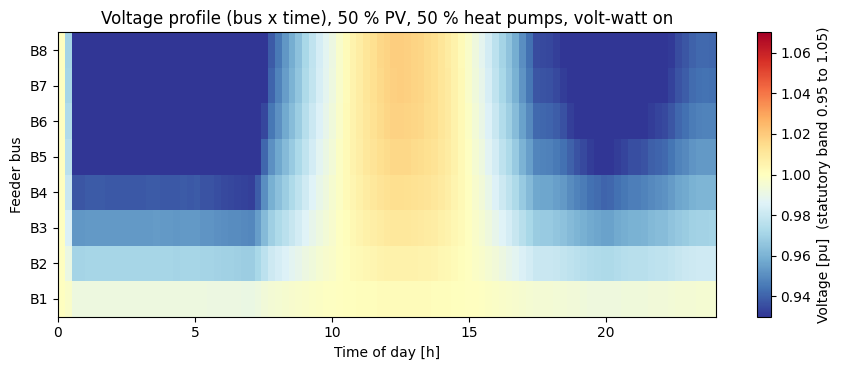

In [7]:
sim_base = make_world(pv_pen=0.5, hp_pen=0.5, volt_watt=True)
res_base = sim_base.simulate(pbar=False)

hours = res_base["feeder.B1.vm_pu"].index / 3600.0
vm_map = np.vstack([res_base[f"feeder.{b}.vm_pu"].values for b in BUS_NAMES])

fig, ax = plt.subplots(figsize=(9, 3.8))
im = ax.imshow(vm_map, aspect="auto", origin="lower", cmap="RdYlBu_r", vmin=0.93, vmax=1.07,
               extent=[hours[0], hours[-1], 0.5, N_BUS + 0.5])
ax.set_yticks(range(1, N_BUS + 1), BUS_NAMES)
ax.set_xlabel("Time of day [h]")
ax.set_ylabel("Feeder bus")
ax.set_title("Voltage profile (bus x time), 50 % PV, 50 % heat pumps, volt-watt on")
cb = fig.colorbar(im, ax=ax)
cb.set_label("Voltage [pu]  (statutory band 0.95 to 1.05)")
plt.tight_layout()
plt.show()

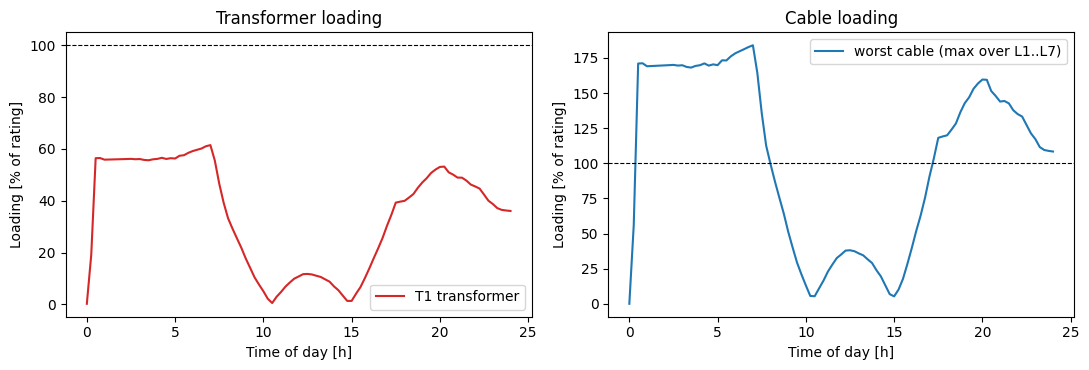

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.plot(hours, res_base["feeder.T1.loading_percent"], label="T1 transformer", color="C3")
ax1.axhline(100.0, color="k", ls="--", lw=0.8)
ax1.set_xlabel("Time of day [h]")
ax1.set_ylabel("Loading [% of rating]")
ax1.set_title("Transformer loading")
ax1.legend()

line_cols = [f"feeder.L{i}.loading_percent" for i in range(1, N_BUS)]
line_max = pd.concat([res_base[c] for c in line_cols], axis=1).max(axis=1)
ax2.plot(hours, line_max, color="C0", label="worst cable (max over L1..L7)")
ax2.axhline(100.0, color="k", ls="--", lw=0.8)
ax2.set_xlabel("Time of day [h]")
ax2.set_ylabel("Loading [% of rating]")
ax2.set_title("Cable loading")
ax2.legend()
plt.tight_layout()
plt.show()

## Ensemble study: hosting capacity

The sweep covers PV penetration (0, 50 and 100 % of homes), heat-pump penetration (0, 50 and 100 %) and the
volt-watt function (off or on): 18 runs. Each run is a fresh world built by `make_world`. To keep the sweep
quick, the runs use a 30-minute macro step (the power flow dominates the run time, so the 15-minute plots above
are the reference). `keep='kpis'` keeps only the KPI table, so memory stays small. The KPIs are:

* `v_max_pu`, `v_min_pu`: extreme voltages over all buses and times,
* `trafo_max_pct`: peak transformer loading,
* `share_outside`: fraction of bus-time samples outside 0.95 to 1.05 pu (the DSO's time-outside-band KPI).

In [9]:
V_COLS = [f"feeder.{b}.vm_pu" for b in BUS_NAMES]


def kpi_v_max(r):
    return max(float(r[c].max()) for c in V_COLS)


def kpi_v_min(r):
    return min(float(r[c].min()) for c in V_COLS)


def kpi_trafo_max(r):
    return float(r["feeder.T1.loading_percent"].max())


def kpi_share_outside(r):
    vals = np.concatenate([r[c].values for c in V_COLS])
    return float(np.mean((vals < 0.95) | (vals > 1.05)))


KPIS = {"v_max_pu": kpi_v_max, "v_min_pu": kpi_v_min,
        "trafo_max_pct": kpi_trafo_max, "share_outside": kpi_share_outside}

study = Ensemble(
    world_factory=lambda params, seed: make_world(t_macro=1800, **params),   # 30 min step: keeps the sweep quick
    sampler=Grid({"pv_pen": [0.0, 0.5, 1.0], "hp_pen": [0.0, 0.5, 1.0], "volt_watt": [False, True]}),
    kpis=KPIS,
    keep="kpis",
).run()

hosting = pd.concat([study.params, study.kpis()], axis=1)
display(hosting.round(3))

C:\Users\digvi\AppData\Local\Temp\ipykernel_8236\3576680021.py:54: UserWarning: Algebraic loop detected involving simulators: ['feeder', 'pv_B1', 'pv_B2', 'pv_B3', 'pv_B4', 'pv_B5', 'pv_B6', 'pv_B7', 'pv_B8']. Using Jacobi coupling (one-step delay) for these cyclic dependencies. Reduce t_macro or merge the coupled components to limit the delay error.
  sim.add_connections(connections)
C:\Users\digvi\AppData\Local\Temp\ipykernel_8236\3576680021.py:54: UserWarning: Algebraic loop detected involving simulators: ['feeder', 'pv_B1', 'pv_B2', 'pv_B3', 'pv_B4', 'pv_B5', 'pv_B6', 'pv_B7', 'pv_B8']. Using Jacobi coupling (one-step delay) for these cyclic dependencies. Reduce t_macro or merge the coupled components to limit the delay error.
  sim.add_connections(connections)
C:\Users\digvi\AppData\Local\Temp\ipykernel_8236\3576680021.py:54: UserWarning: Algebraic loop detected involving simulators: ['feeder', 'pv_B1', 'pv_B2', 'pv_B3', 'pv_B4', 'pv_B5', 'pv_B6', 'pv_B7', 'pv_B8']. Using Jacobi c

,pv_pen,hp_pen,volt_watt,seed,v_max_pu,v_min_pu,trafo_max_pct,share_outside
run,,,,,,,,
0,0.0,0.0,False,3757552657,1.000,0.930,44.298,0.184
1,0.0,0.0,True,673228719,1.000,0.930,44.298,0.184
2,0.0,0.5,False,3241444873,1.000,0.898,61.329,0.474
3,0.0,0.5,True,3685993406,1.000,0.898,61.329,0.474
4,0.0,1.0,False,1216546553,1.000,0.872,77.883,0.617
5,0.0,1.0,True,2078861726,1.000,0.872,77.883,0.617
6,0.5,0.0,False,2471122328,1.038,0.930,44.298,0.184
7,0.5,0.0,True,23012616,1.037,0.930,44.298,0.184
8,0.5,0.5,False,3031610183,1.018,0.898,61.329,0.342


## Hosting-capacity heat maps

Each panel shows one KPI as a function of PV penetration (rows) and heat-pump penetration (columns), with
volt-watt off on the left and on at the right. Cells above the statutory limit are the ones to read.
For `share_outside`, 0 is ideal. For `trafo_max_pct`, values above 100 % mean the transformer is overloaded.

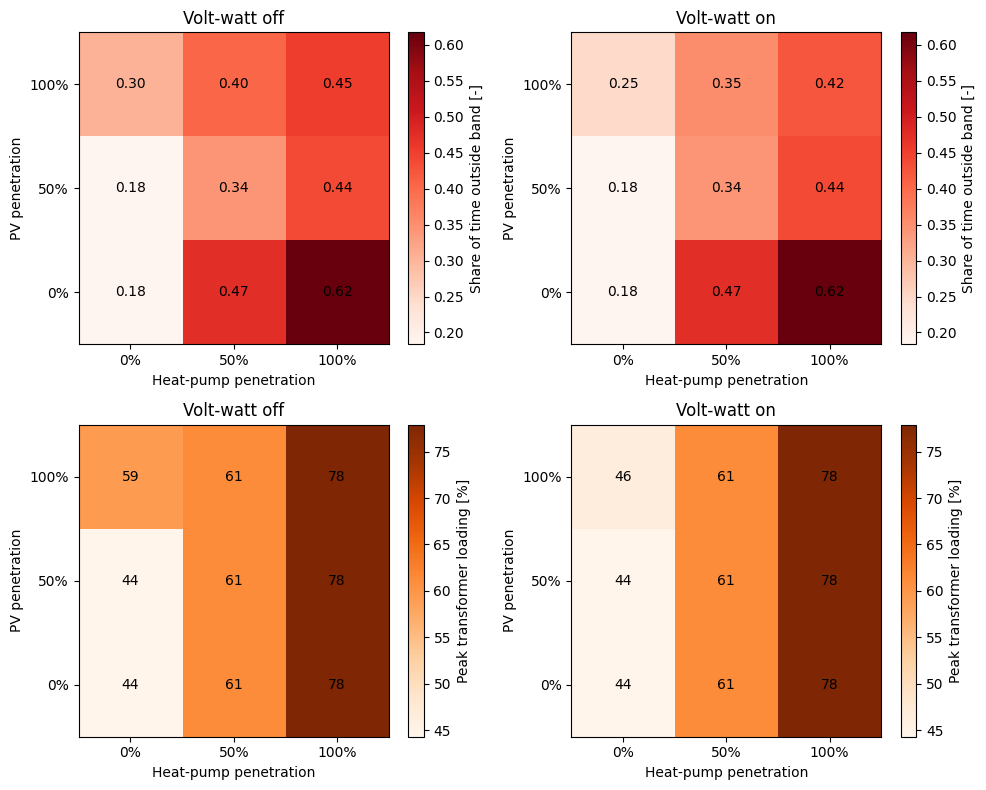

In [10]:
def pivot_kpi(table, kpi, volt_watt):
    sub = table[table["volt_watt"] == volt_watt]
    return sub.pivot(index="pv_pen", columns="hp_pen", values=kpi).sort_index(ascending=True)


fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for col, vw in enumerate([False, True]):
    for row, (kpi, cmap, label) in enumerate([("share_outside", "Reds", "Share of time outside band [-]"),
                                              ("trafo_max_pct", "Oranges", "Peak transformer loading [%]")]):
        ax = axes[row, col]
        piv = pivot_kpi(hosting, kpi, vw)
        im = ax.imshow(piv.values, origin="lower", cmap=cmap, aspect="auto")
        ax.set_xticks(range(len(piv.columns)), [f"{c:.0%}" for c in piv.columns])
        ax.set_yticks(range(len(piv.index)), [f"{r:.0%}" for r in piv.index])
        ax.set_xlabel("Heat-pump penetration")
        ax.set_ylabel("PV penetration")
        ax.set_title(f"{'Volt-watt on' if vw else 'Volt-watt off'}")
        for i in range(piv.shape[0]):
            for j in range(piv.shape[1]):
                ax.text(j, i, f"{piv.values[i, j]:.2f}" if kpi == "share_outside" else f"{piv.values[i, j]:.0f}",
                        ha="center", va="center", color="k")
        cb = fig.colorbar(im, ax=ax)
        cb.set_label(label)
plt.tight_layout()
plt.show()

## What to read from the results

* With **volt-watt off**, high PV penetration is expected to push the far-end buses above 1.05 pu around
  midday, because reverse power flow lifts the voltage along the feeder. This is the usual constraint on rooftop PV.
  The `share_outside` column shows where it happens.
* With **volt-watt on**, the inverters should curtail as the voltage rises, which should lower `share_outside` at
  high PV. The price is curtailed energy. That is not in the KPIs here, but an `available - delivered` energy KPI
  would show it.
* **Heat pumps and EV charging coincide in the evening.** The transformer peak is expected to move most with
  heat-pump penetration, because the night-time load is the largest.

Caveats: unity power factor, a single 24 h winter day, one heat-pump model, a 30-minute step in the sweep, and a
one-step delay in the volt-watt loop (damped by a 30-minute fleet response). Use this study to compare options and
to find the order of magnitude of the limit, not as a final planning number.

## Where to go next

* **Notebook 14** couples the power system with a gas network during a multi-day cold snap, where the heat-pump
  fleet and its COP collapse become a system question.
* **Notebook 03** shows how to write your own `ModelComponent`, and **notebook 06** how the vectorized fleets scale
  to tens of thousands of units.
* For a feeder with real measurements, replace the synthetic profiles with smart-meter data and add reactive power
  (`q_mvar`) from heat pumps and inverters. The files in `snippets/` can be copied into your project as they are.